In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import scipy as sp
from scipy.odr import *
import random

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [2]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=1)))
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=1)))
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=1)))
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=1)))

In [3]:
print(np.shape(M0StarData),np.shape(M1StarData),np.shape(C0StarData),np.shape(C1StarData))

(29, 1950) (29, 2162) (28, 1994) (27, 781)


With this data, we need to do 3 different fits on each: Mdot(L, P, M) or Mdot(L,R,M) or Mdot(L,P,R). We should see that all of them are valid, confirming the fits we did earlier worked. For practical use Mdot(L, P, M) will be most useful because L and P are observable values and M can be estimated by calculating from L and P in a non-trivial way.

In [4]:
MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
#MdotIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data

In [5]:
DataToFit=M0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])

# Testing: What happens with a fit of LvR, PvR, LvM, or PvM?

In [6]:
def CriticalZoneOnly (DataToTrim,logLowerBound,logUpperBound): # Function to restrict an imported data set
    # to only stars in the critical mass loss range
    CuttingArray = []
    i = 0
    Cleaned_Set = np.transpose(DataToTrim)
    while i<len(DataToTrim[MdotIndex]):
        if np.log10(DataToTrim[MdotIndex][i]) < logLowerBound: # If logMdot is lesser than the declared lower bound
            CuttingArray.append(i) # Add this row to the list of rows to be cut
        elif np.log10(DataToTrim[MdotIndex][i]) > logUpperBound: # If logMdot is greater than the declared upper bound
            CuttingArray.append(i) # Add this row to the list of rows to be cut
        i += 1 # Move to the next row
    Cleaned_Set = np.delete(Cleaned_Set,CuttingArray,axis=0)
    print ('Entries Removed:',len(CuttingArray))
    print ('Stars Remaining:', len(Cleaned_Set))
    return np.transpose(Cleaned_Set)

In [7]:
DataToFit = CriticalZoneOnly(DataToFit,-7,-5)

Entries Removed: 483
Stars Remaining: 1467


In [8]:
DataToFit=M0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
DataToFit = CriticalZoneOnly(DataToFit,-8,-5)
# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])

Entries Removed: 6
Stars Remaining: 1944


In [9]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x + B[1] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData(logRData, logLData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[0,0]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [ 1.83721863 -0.49230813]
Beta Std Error: [0.00759389 0.01663077]
Beta Covariance: [[ 0.27818364 -0.60871357]
 [-0.60871357  1.33422054]]
Residual Variance: 0.00020729887134415727
Inverse Condition #: 0.013042327626495896
Reason(s) for Halting:
  Sum of squares convergence


In [10]:
out.pprint()

Beta: [ 1.83721863 -0.49230813]
Beta Std Error: [0.00759389 0.01663077]
Beta Covariance: [[ 0.27818364 -0.60871357]
 [-0.60871357  1.33422054]]
Residual Variance: 0.00020729887134415727
Inverse Condition #: 0.013042327626495896
Reason(s) for Halting:
  Sum of squares convergence


In [11]:
LvRFit = 1.83721863*logRData -0.49230813

Text(0, 0.5, 'logL')

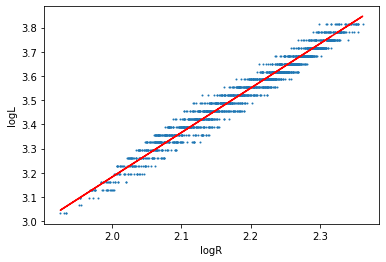

In [12]:
plot.scatter(logRData, logLData, s=1)
plot.plot(logRData, LvRFit,color="red")
plot.xlabel("logR")
plot.ylabel("logL")

In [13]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x + B[1] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData(logRData, logPData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[0,0]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [ 1.55154866 -1.19986197]
Beta Std Error: [0.01800413 0.03942591]
Beta Covariance: [[ 0.24018932 -0.52557237]
 [-0.52557237  1.15178849]]
Residual Variance: 0.0013495552883777565
Inverse Condition #: 0.01238006202455714
Reason(s) for Halting:
  Sum of squares convergence


In [14]:
PvRFit = 1.55154866*logRData -1.19986197

Text(0, 0.5, 'logP')

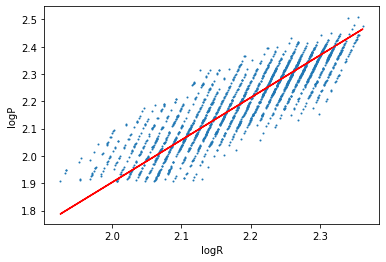

In [15]:
plot.scatter(logRData, logPData, s=1)
plot.plot(logRData, PvRFit,color="red")
plot.xlabel("logR")
plot.ylabel("logP")

In [16]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x + B[1] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData(logMData, logLData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[0,0]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [1.4946389  3.50954034]
Beta Std Error: [0.0206764 0.0022625]
Beta Covariance: [[ 0.14068643 -0.00172035]
 [-0.00172035  0.00168454]]
Residual Variance: 0.0030387687069802862
Inverse Condition #: 0.11760829031404996
Reason(s) for Halting:
  Sum of squares convergence


In [17]:
LvMFit = 1.4946389*logMData + 3.50954034

Text(0, 0.5, 'logL')

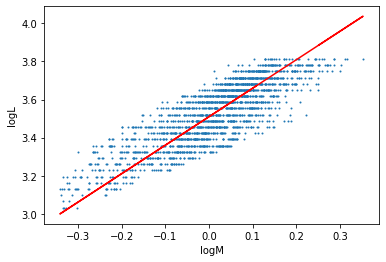

In [18]:
plot.scatter(logMData, logLData, s=1)
plot.plot(logMData, LvMFit,color="red")
plot.xlabel("logM")
plot.ylabel("logL")

In [19]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x + B[1] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData(logMData, logPData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[0,0]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [1.50467171 2.17677354]
Beta Std Error: [0.05273489 0.00429453]
Beta Covariance: [[ 0.25901689 -0.00316727]
 [-0.00316727  0.00171776]]
Residual Variance: 0.010736629747271196
Inverse Condition #: 0.08532715559070302
Reason(s) for Halting:
  Sum of squares convergence


In [20]:
PvMFit = 1.50467171*logMData + 2.17677354

Text(0, 0.5, 'logP')

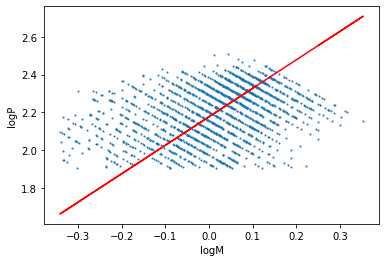

In [21]:
plot.scatter(logMData, logPData, s=1)
plot.plot(logMData, PvMFit,color="red")
plot.xlabel("logM")
plot.ylabel("logP")

In [22]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x + B[1] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData(logMData, logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[0,0]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [-20.3528249   -6.52307144]
Beta Std Error: [2.84924854 0.06419592]
Beta Covariance: [[ 5.96482305e+02 -7.29424456e+00]
 [-7.29424456e+00  3.02797105e-01]]
Residual Variance: 0.013610156022187573
Inverse Condition #: 0.01903763170942563
Reason(s) for Halting:
  Sum of squares convergence


(-9, -5)

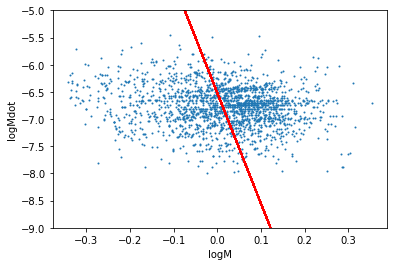

In [23]:
MdotvMFit =-20.3528249 *logMData -6.52307144
plot.scatter(logMData, logMdotData, s=1)
plot.plot(logMData, MdotvMFit,color="red")
plot.xlabel("logM")
plot.ylabel("logMdot")
plot.ylim(-9, -5)

In [24]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x + B[1] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData(logLData, logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[0,0]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [ 16.66952831 -65.57902193]
Beta Std Error: [2.69144664 9.4951374 ]
Beta Covariance: [[ 268.83983102 -948.41799068]
 [-948.41799068 3345.9894971 ]]
Residual Variance: 0.026944984247921897
Inverse Condition #: 0.0014481897824107472
Reason(s) for Halting:
  Sum of squares convergence


(-9, -5)

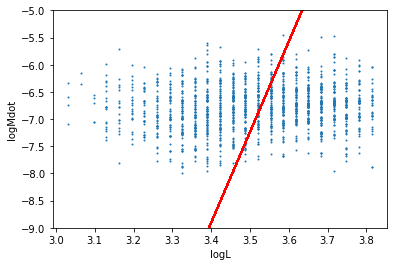

In [25]:
MdotvLFit = 16.66952831 *logLData - 65.57902193
plot.scatter(logLData, logMdotData, s=1)
plot.plot(logLData, MdotvLFit,color="red")
plot.xlabel("logL")
plot.ylabel("logMdot")
plot.ylim(-9, -5)

In [26]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x + B[1] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData(logPData, logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[0,0]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [  7.10794534 -22.3751314 ]
Beta Std Error: [0.37251511 0.81798363]
Beta Covariance: [[  9.04310539 -19.85117772]
 [-19.85117772  43.60326613]]
Residual Variance: 0.015345117046731332
Inverse Condition #: 0.00777428898279884
Reason(s) for Halting:
  Sum of squares convergence


(-9, -5)

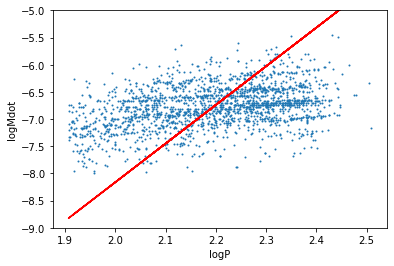

In [27]:
MdotvPFit =  7.10794534*logPData -22.3751314
plot.scatter(logPData, logMdotData, s=1)
plot.plot(logPData, MdotvPFit,color="red")
plot.xlabel("logP")
plot.ylabel("logMdot")
plot.ylim(-9, -5)

In [28]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x + B[1] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData(logRData, logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[0,0]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [ 20.9996898  -52.72261742]
Beta Std Error: [2.3164215  5.06887581]
Beta Covariance: [[  675.83750619 -1478.83968449]
 [-1478.83968449  3236.16320566]]
Residual Variance: 0.007939495113457491
Inverse Condition #: 0.0026359250449991675
Reason(s) for Halting:
  Sum of squares convergence


(-9, -5)

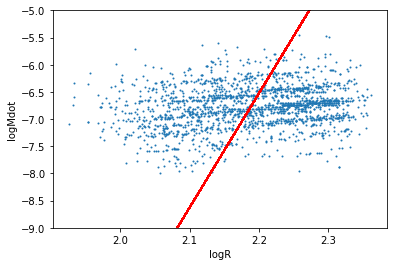

In [29]:
MdotvRFit = 20.9996898*logRData -52.72261742
plot.scatter(logRData, logMdotData, s=1)
plot.plot(logRData, MdotvRFit,color="red")
plot.xlabel("logR")
plot.ylabel("logMdot")
plot.ylim(-9, -5)

# Mdot Fits

In [30]:
DataToFit=M0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
DataToFit = CriticalZoneOnly(DataToFit,-8,-5)
# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])
WRatio = 0.67
logPdivLData = np.log10((DataToFit[PIndex]/DataToFit[LIndex])**WRatio)

Entries Removed: 6
Stars Remaining: 1944


In [31]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
x1 = logPData
y = logMdotData

x0Delta = logLDataError
x1Delta = 1 # No error in P
yDelta = logMdotDataError

data = pandas.DataFrame({'logL': x0, 'logP': x1, 'logMdot': y})
weightsFrame = pandas.DataFrame({'logLError': x0Delta, 'logPError': x1Delta, 'yDelta': logMdotDataError })

# Fit the model
model = wls("logMdot ~ logL + logP", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                logMdot   R-squared:                       0.204
Model:                            WLS   Adj. R-squared:                  0.203
Method:                 Least Squares   F-statistic:                     248.2
Date:                Tue, 02 Jun 2020   Prob (F-statistic):           1.07e-96
Time:                        20:19:15   Log-Likelihood:                -682.47
No. Observations:                1944   AIC:                             1371.
Df Residuals:                    1941   BIC:                             1388.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -7.6446      0.167    -45.877      0.0

In [32]:
np.std(logLData)

0.1653907025409995

In [33]:
meanMdotError = np.mean(10**logMdotDataError/10**logMdotData)
meanLError = np.mean(10**logLDataError/10**logLData)

In [34]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logLData, logPData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [-7.5573466  10.6568775  -3.50470881]
Beta Std Error: [0.39978479 0.52074141 0.45843275]
Beta Covariance: [[ 40.37751384 -50.33664749 -31.94687263]
 [-50.33664749  68.5064204   27.19509257]
 [-31.94687263  27.19509257  53.09312757]]
Residual Variance: 0.003958338774077242
Inverse Condition #: 0.005759344727318942
Reason(s) for Halting:
  Sum of squares convergence


In [35]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logLData, logPData), y=logMdotData, sx=(np.std(logLData),np.std(logPData)), sy =np.std(logMdotData)) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [-6.68527827  9.10645057 -3.17775207]
Beta Std Error: [0.31139733 0.38780975 0.40646441]
Beta Covariance: [[ 0.53977164 -0.6349113  -0.51047603]
 [-0.6349113   0.83717785  0.40210141]
 [-0.51047603  0.40210141  0.91965582]]
Residual Variance: 0.1796468966810999
Inverse Condition #: 0.006529552621948931
Reason(s) for Halting:
  Sum of squares convergence


In [36]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logLData, logPData), y=logMdotData, sx=(meanLError,np.std(logPData)), sy =meanMdotError) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [-5.59704259  8.76534189 -6.26805678]
Beta Std Error: [0.24930287 0.34757531 0.32840067]
Beta Covariance: [[ 0.23253291 -0.30147739 -0.1585388 ]
 [-0.30147739  0.45198883  0.07136375]
 [-0.1585388   0.07136375  0.4034948 ]]
Residual Variance: 0.2672822608069985
Inverse Condition #: 0.00784548976090025
Reason(s) for Halting:
  Sum of squares convergence


In [37]:
logMdot_LP_RealErrors = -5.59704259 * logLData + 8.76534189*logPData -6.26805678
logMdot_LP_StdErrors = -6.68527827 * logLData + 9.10645057*logPData -3.17775207
logMdot_LP_NoErrors = -7.5573466 * logLData + 10.6568775*logPData -3.50470881

In [38]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_LP_RealErrors

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_LP': y})

# Fit the model
model = ols("logMdot_LP ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
LPRealErrorsLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

In [39]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_LP_StdErrors

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_LP': y})

# Fit the model
model = ols("logMdot_LP ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
LPStdErrorsLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

In [40]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_LP_NoErrors

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_LP': y})

# Fit the model
model = ols("logMdot_LP ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
LPNoErrorsLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

Comparison to Observed: logMdot_calc = ( -0.1804253209781438 ) + ( 0.9733570178831799 )*logMdot_obsv


Text(0.5, 1.0, 'No Errors Included')

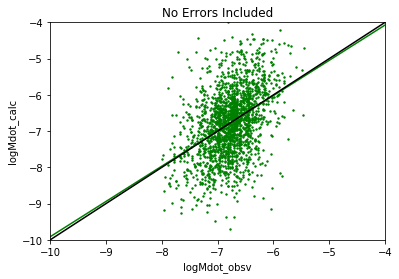

In [41]:
SlopeTestNoErrors=LPNoErrorsLine[0] + LPNoErrorsLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',LPNoErrorsLine[0],') + (',LPNoErrorsLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, logMdot_LP_NoErrors, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('No Errors Included')

Comparison to Observed: logMdot_calc = ( -1.2150075713119945 ) + ( 0.8205826835749306 )*logMdot_obsv


Text(0.5, 1.0, 'Errors from Std. Dev. Included')

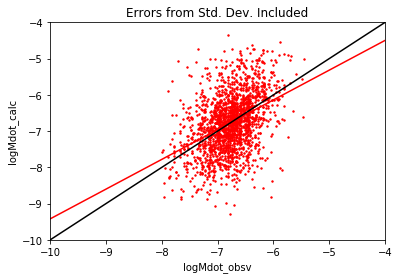

In [42]:
#SlopeTest=-5.39295267 + 0.20363534 *(np.asarray([-8,-7,-6,-5,-4,-3]))
SlopeTestStdErrors=LPStdErrorsLine[0] + LPStdErrorsLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
#plot.scatter(logMdotData, logMdot_LP_NoErrors, s=2)
plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2, color='red')
print('Comparison to Observed:','logMdot_calc = (',LPStdErrorsLine[0],') + (',LPStdErrorsLine[1],')*logMdot_obsv')
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestStdErrors, color='red')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('Errors from Std. Dev. Included')

Comparison to Observed: logMdot_calc = ( -1.1446281248835657 ) + ( 0.8309754523304281 )*logMdot_obsv


Text(0.5, 1.0, '"Real" Errors Included')

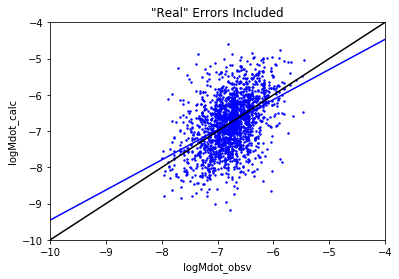

In [43]:
#SlopeTest=-5.39295267 + 0.20363534 *(np.asarray([-8,-7,-6,-5,-4,-3]))
SlopeTestRealErrors=LPRealErrorsLine[0] + LPRealErrorsLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
#plot.scatter(logMdotData, logMdot_LP_NoErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2, color='blue')
print('Comparison to Observed:','logMdot_calc = (',LPRealErrorsLine[0],') + (',LPRealErrorsLine[1],')*logMdot_obsv')
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
#plot.plot(np.asarray([-8,-7,-6,-5,-4,-3]),SlopeTest)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestRealErrors, color='blue')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('"Real" Errors Included')

Text(0.5, 1.0, 'Overlay Comparison')

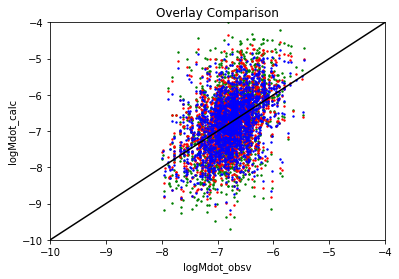

In [44]:
#SlopeTest=-5.39295267 + 0.20363534 *(np.asarray([-8,-7,-6,-5,-4,-3]))
plot.scatter(logMdotData, logMdot_LP_NoErrors, s=2, color='green')
plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2, color='red')
plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2, color='blue')
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
#plot.plot(np.asarray([-8,-7,-6,-5,-4,-3]),SlopeTest)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('Overlay Comparison')

# Mdot vs L, P, M

In [45]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
x1 = logPData
x2 = logMData
y = logMdotData

x0Delta = logLDataError
x1Delta = 1 # No error in P
yDelta = logMdotDataError

data = pandas.DataFrame({'logL': x0, 'logP': x1, 'logM': x2, 'logMdot': y})

# Fit the model
model = wls("logMdot ~ logL + logP + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                logMdot   R-squared:                       0.204
Model:                            WLS   Adj. R-squared:                  0.203
Method:                 Least Squares   F-statistic:                     248.2
Date:                Tue, 02 Jun 2020   Prob (F-statistic):           1.07e-96
Time:                        20:19:16   Log-Likelihood:                -682.47
No. Observations:                1944   AIC:                             1371.
Df Residuals:                    1941   BIC:                             1388.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.7044      0.062    -59.448      0.0

In [46]:
model._results.params[0]

-3.704364379493974

In [47]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2]*x[2] + B[3] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logLData, logPData, logMData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[3],model._results.params[0]],maxit=10000) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [-2615.86308033  1872.17527657  2410.01300271  5082.29794682]
Beta Std Error: [ 59.36995782  42.46191576  54.71887287 115.5662079 ]
Beta Covariance: [[ 4.80963828e+11 -3.43989202e+11 -4.43284421e+11 -9.36216402e+11]
 [-3.43989202e+11  2.46024356e+11  3.17040410e+11  6.69588391e+11]
 [-4.43284421e+11  3.17040410e+11  4.08557531e+11  8.62872224e+11]
 [-9.36216402e+11  6.69588391e+11  8.62872224e+11  1.82238722e+12]]
Residual Variance: 7.328600789331048e-09
Inverse Condition #: 8.128110030315202e-06
Reason(s) for Halting:
  Sum of squares convergence


In [48]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2]*x[2] + B[3] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logLData, logPData, logMData), y=logMdotData, sx=(np.std(logLData),np.std(logPData),np.std(logMData)), sy =np.std(logMdotData)) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[3],model._results.params[0]],maxit=5000) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [-17341.85848321  12404.31389824  15982.3589088   33747.09680021]
Beta Std Error: [393.60124687 281.5065087  362.76611875 766.16209653]
Beta Covariance: [[ 1.90332231e+13 -1.36127009e+13 -1.75421404e+13 -3.70490033e+13]
 [-1.36127009e+13  9.73590413e+12  1.25462675e+13  2.64977182e+13]
 [-1.75421404e+13  1.25462675e+13  1.61678713e+13  3.41465459e+13]
 [-3.70490033e+13  2.64977182e+13  3.41465459e+13  7.21175116e+13]]
Residual Variance: 8.13955369383484e-09
Inverse Condition #: 1.2250981267766054e-06
Reason(s) for Halting:
  Iteration limit reached


In [49]:
logMdot_LPM = -3.70436438  -3.02322566*logLData +3.4507427 *logPData + 1.8656414*logMData

In [50]:
logMdot_LPM_ODR = 202.82862378 -109.18369294*logLData + 79.42778784*logPData + 99.71259934*logMData

In [51]:
#logMdot_LPM_ODR_2= 195.41503297 -115.97490609*logLData + 102.2770426*logPData + 111.23788184*logMData

In [52]:
np.mean(logMdotData-logMdot_LPM_ODR)

0.002560910100351264

(-9, -5)

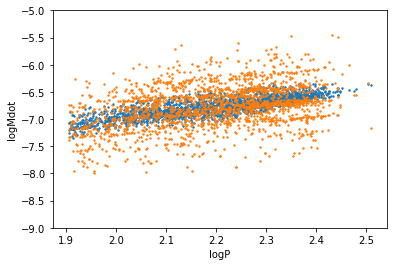

In [53]:
plot.scatter(logPData, logMdot_LPM_ODR, s=2)
plot.scatter(logPData, logMdotData, s=2)
plot.xlabel("logP")
plot.ylabel("logMdot")
plot.ylim(-9, -5)

(-9, -5)

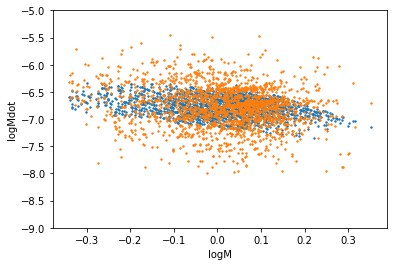

In [54]:
plot.scatter(logMData, logMdot_LPM_ODR, s=2)
plot.scatter(logMData, logMdotData, s=2)
plot.xlabel("logM")
plot.ylabel("logMdot")
plot.ylim(-9, -5)

(-9, -5)

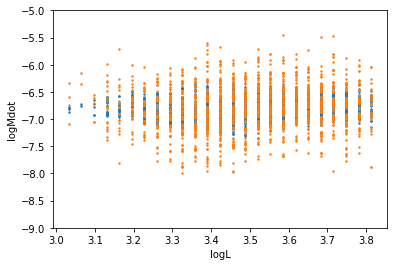

In [55]:
plot.scatter(logLData, logMdot_LPM_ODR, s=2)
plot.scatter(logLData, logMdotData, s=2)
plot.xlabel("logL")
plot.ylabel("logMdot")
plot.ylim(-9, -5)

In [56]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_LPM

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_LPM': y})

# Fit the model
model = ols("logMdot_LPM ~ logMdotData", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:            logMdot_LPM   R-squared:                       0.204
Model:                            OLS   Adj. R-squared:                  0.203
Method:                 Least Squares   F-statistic:                     496.6
Date:                Tue, 02 Jun 2020   Prob (F-statistic):           3.82e-98
Time:                        20:19:43   Log-Likelihood:                 864.39
No. Observations:                1944   AIC:                            -1725.
Df Residuals:                    1942   BIC:                            -1714.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -5.3930      0.062    -87.007      

(-8, -4)

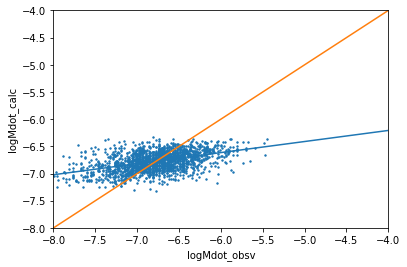

In [57]:
SlopeTest=-5.39295267 + 0.20363534 *(np.asarray([-8,-7,-6,-5,-4,-3]))
plot.scatter(logMdotData, logMdot_LPM, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-8,-7,-6,-5,-4,-3]),SlopeTest)
plot.plot(np.asarray([-8,-7,-6,-5,-4,-3]),np.asarray([-8,-7,-6,-5,-4,-3]))
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-8, -4)
plot.ylim(-8, -4)

# Mdot vs L, P, T

In [58]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
x1 = logPData
x2 = logTeffObsvData
y = logMdotData

data = pandas.DataFrame({'logL': x0, 'logP': x1, 'logT': x2, 'logMdot': y})

# Fit the model
model = wls("logMdot ~ logL + logP + logT", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                logMdot   R-squared:                       0.204
Model:                            WLS   Adj. R-squared:                  0.202
Method:                 Least Squares   F-statistic:                     165.4
Date:                Tue, 02 Jun 2020   Prob (F-statistic):           1.90e-95
Time:                        20:19:43   Log-Likelihood:                -682.47
No. Observations:                1944   AIC:                             1373.
Df Residuals:                    1940   BIC:                             1395.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -7.5725      0.748    -10.120      0.0

In [59]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2]*x[2] + B[3] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logLData, logPData, logTeffObsvData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[3],model._results.params[0]],maxit=1000) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [ -23.3653315    38.89338344   71.2604878  -262.8542813 ]
Beta Std Error: [ 4.34456743  7.13645686 13.74737934 49.26592315]
Beta Covariance: [[  16011.3248578   -26189.11225742  -50086.50685302  178923.10784693]
 [ -26189.11225742   43201.56456687   82681.80174926 -296148.80664904]
 [ -50086.50685302   82681.80174926  160314.94790402 -574279.46089969]
 [ 178923.10784693 -296148.80664904 -574279.46089969 2058862.93508651]]
Residual Variance: 0.0011788697257659915
Inverse Condition #: 1.2295878773616836e-05
Reason(s) for Halting:
  Sum of squares convergence


In [60]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2]*x[2] + B[3] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logLData, logPData, logTeffObsvData), y=logMdotData, sx=(np.std(logLData),np.std(logPData),np.std(logTeffObsvData)), sy =np.std(logMdotData)) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[3],model._results.params[0]],maxit=1000) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

Beta: [-10.96842993  16.54665793  17.06442739 -65.01679185]
Beta Std Error: [0.71903209 1.04311615 1.29376137 4.45449162]
Beta Covariance: [[  4.53690497  -6.45011975  -7.44802796  24.6108207 ]
 [ -6.45011975   9.54835326  11.08498834 -37.58180521]
 [ -7.44802796  11.08498834  14.68829893 -50.23431466]
 [ 24.6108207  -37.58180521 -50.23431466 174.12431959]]
Residual Variance: 0.11395591160730309
Inverse Condition #: 4.594984145566283e-05
Reason(s) for Halting:
  Sum of squares convergence


In [61]:
logMdot_LPT_NoErrors = -23.3653315 * logLData + 38.89338344*logPData + 71.2604878*logTeffObsvData - 262.8542813 
logMdot_LPT_StdErrors = -10.96842993 * logLData + 16.54665793*logPData + 17.06442739*logTeffObsvData - 65.01679185

In [62]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_LPT_NoErrors

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_LP': y})

# Fit the model
model = ols("logMdot_LP ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
LPTNoErrorsLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

In [63]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_LPT_StdErrors

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_LP': y})

# Fit the model
model = ols("logMdot_LP ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
LPTStdErrorsLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

Comparison to Observed: logMdot_calc = ( -0.05356026195219736 ) + ( 0.9920908823960939 )*logMdot_obsv


Text(0.5, 1.0, 'No Errors Included')

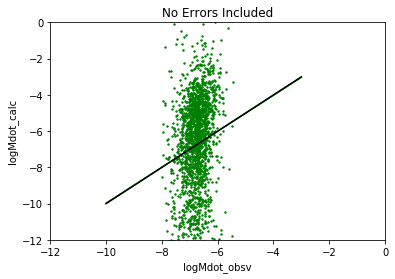

In [64]:
SlopeTestNoErrors=LPTNoErrorsLine[0] + LPTNoErrorsLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',LPTNoErrorsLine[0],') + (',LPTNoErrorsLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, logMdot_LPT_NoErrors, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-12, 0)
plot.ylim(-12, 0)
plot.title('No Errors Included')

Comparison to Observed: logMdot_calc = ( -0.7704196773958111 ) + ( 0.8862339352344286 )*logMdot_obsv


Text(0.5, 1.0, 'Errors from Std. Dev. Included')

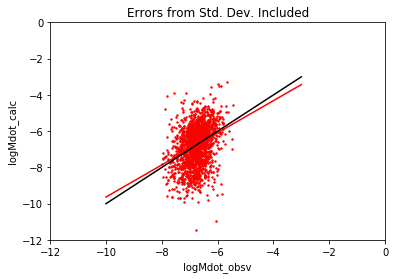

In [65]:
#SlopeTest=-5.39295267 + 0.20363534 *(np.asarray([-8,-7,-6,-5,-4,-3]))
SlopeTestStdErrors=LPTStdErrorsLine[0] + LPTStdErrorsLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
#plot.scatter(logMdotData, logMdot_LP_NoErrors, s=2)
plot.scatter(logMdotData, logMdot_LPT_StdErrors, s=2, color='red')
print('Comparison to Observed:','logMdot_calc = (',LPTStdErrorsLine[0],') + (',LPTStdErrorsLine[1],')*logMdot_obsv')
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestStdErrors, color='red')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-12, 0)
plot.ylim(-12, 0)
plot.title('Errors from Std. Dev. Included')

# Mdot vs (P/L^W), T

In [94]:
DataToFit=M0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
DataToFit = CriticalZoneOnly(DataToFit,-8,-5)
# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])
WRatio = 0.7
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio))

Entries Removed: 6
Stars Remaining: 1944


In [95]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPdivLWData
x1 = logMData
y = logMdotData

data = pandas.DataFrame({'logPdivLW': x0, 'logM': x1, 'logMdot': y})

# Fit the model
model = wls("logMdot ~ logPdivLW + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                logMdot   R-squared:                       0.204
Model:                            WLS   Adj. R-squared:                  0.203
Method:                 Least Squares   F-statistic:                     248.2
Date:                Tue, 02 Jun 2020   Prob (F-statistic):           1.07e-96
Time:                        21:33:43   Log-Likelihood:                -682.47
No. Observations:                1944   AIC:                             1371.
Df Residuals:                    1941   BIC:                             1388.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -6.0733      0.034   -179.769      0.0

In [96]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logPdivLWData, logMData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
outPdivLW_M = odr.run()

# Use the in-built pprint method to give us results.
outPdivLW_M.pprint()

Beta: [14.54610496  7.91103015 -2.8787093 ]
Beta Std Error: [0.74143746 0.4601622  0.19909883]
Beta Covariance: [[206.35042978 119.19769193  55.14428659]
 [119.19769193  79.48372496  31.72394684]
 [ 55.14428659  31.72394684  14.87968439]]
Residual Variance: 0.0026640580035821536
Inverse Condition #: 0.015885490508181853
Reason(s) for Halting:
  Sum of squares convergence


In [97]:
outPdivLW_M.beta

array([14.54610496,  7.91103015, -2.8787093 ])

In [98]:
print( 'logMdot =', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM + ', outPdivLW_M.beta[2])

logMdot = 14.546104964558715 log(P/L^W) +  7.911030151066557 logM +  -2.878709303610485


In [99]:
logMdot_PdivLM = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2]

In [100]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_PdivLM

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
PdivLMLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

Comparison to Observed: logMdot_calc = ( -0.1214216667010639 ) + ( 0.9820699592755389 )*logMdot_obsv


Text(0.5, 1.0, 'No Errors Included')

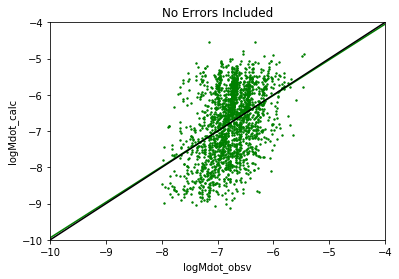

In [101]:
SlopeTestNoErrors=PdivLMLine[0] + PdivLMLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',PdivLMLine[0],') + (',PdivLMLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, logMdot_PdivLM, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('No Errors Included')

# Mdot ~ L, M

In [ ]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
x1 = logMData
y = logMdotData

x0Delta = logLDataError
x1Delta = 1 # No error in P
yDelta = logMdotDataError

data = pandas.DataFrame({'logL': x0, 'logM': x1, 'logMdot': y})
weightsFrame = pandas.DataFrame({'logLError': x0Delta, 'logPError': x1Delta, 'yDelta': logMdotDataError })

# Fit the model
model = wls("logMdot ~ logL + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

In [ ]:
meanMdotError = np.mean(10**logMdotDataError/10**logMdotData)
meanLError = np.mean(10**logLDataError/10**logLData)

In [ ]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logLData, logMData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

In [ ]:
LM_Fit_No_error = out.beta[0]*logLData + out.beta[1]*logMData + out.beta[2]
print('Fit (No Errors Included): logMdot = (', out.beta[0], ')logL + (',out.beta[1],')logM + (',out.beta[2],')' )

In [ ]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logLData, logMData), y=logMdotData, sx=(np.std(logLData),np.std(logMData)), sy =np.std(logMdotData)) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

In [ ]:
LM_Fit_SD_error = out.beta[0]*logLData + out.beta[1]*logMData + out.beta[2]
print('Fit (SD Errors Included): logMdot = (', out.beta[0], ')logL + (',out.beta[1],')logM + (',out.beta[2],')' )

In [ ]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logLData, logMData), y=logMdotData, sx=(meanLError,np.std(logMData)), sy =meanMdotError) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
out = odr.run()

# Use the in-built pprint method to give us results.
out.pprint()

In [ ]:
LM_Fit_Real_error = out.beta[0]*logLData + out.beta[1]*logMData + out.beta[2]
print('Fit (Real Errors Included): logMdot = (', out.beta[0], ')logL + (',out.beta[1],')logM + (',out.beta[2],')' )

In [ ]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = LM_Fit_No_error

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_LM': y})

# Fit the model
model = ols("logMdot_LM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
LMNoErrorsLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

In [ ]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = LM_Fit_SD_error

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_LM': y})

# Fit the model
model = ols("logMdot_LM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
LMStdErrorsLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

In [ ]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = LM_Fit_Real_error

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_LM': y})

# Fit the model
model = ols("logMdot_LM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
LMRealErrorsLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

In [ ]:
SlopeTestNoErrors=LMNoErrorsLine[0] + LMNoErrorsLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',LMNoErrorsLine[0],') + (',LMNoErrorsLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, LM_Fit_No_error, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('No Errors Included')

In [ ]:
#SlopeTest=-5.39295267 + 0.20363534 *(np.asarray([-8,-7,-6,-5,-4,-3]))
SlopeTestStdErrors=LMStdErrorsLine[0] + LMStdErrorsLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
#plot.scatter(logMdotData, logMdot_LP_NoErrors, s=2)
plot.scatter(logMdotData, LM_Fit_SD_error, s=2, color='red')
print('Comparison to Observed:','logMdot_calc = (',LMStdErrorsLine[0],') + (',LMStdErrorsLine[1],')*logMdot_obsv')
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestStdErrors, color='red')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('Errors from Std. Dev. Included')

In [ ]:
#SlopeTest=-5.39295267 + 0.20363534 *(np.asarray([-8,-7,-6,-5,-4,-3]))
SlopeTestRealErrors=LMRealErrorsLine[0] + LMRealErrorsLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
#plot.scatter(logMdotData, logMdot_LP_NoErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
plot.scatter(logMdotData, LM_Fit_Real_error, s=2, color='blue')
print('Comparison to Observed:','logMdot_calc = (',LMRealErrorsLine[0],') + (',LMRealErrorsLine[1],')*logMdot_obsv')
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
#plot.plot(np.asarray([-8,-7,-6,-5,-4,-3]),SlopeTest)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestRealErrors, color='blue')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('"Real" Errors Included')

In [ ]:
#SlopeTest=-5.39295267 + 0.20363534 *(np.asarray([-8,-7,-6,-5,-4,-3]))
plot.scatter(logMdotData, LM_Fit_No_error, s=1, color='green')
plot.scatter(logMdotData, LM_Fit_SD_error, s=1, color='red')
plot.scatter(logMdotData, LM_Fit_Real_error, s=1, color='blue')
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
#plot.plot(np.asarray([-8,-7,-6,-5,-4,-3]),SlopeTest)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('Overlay Comparison')

In [ ]:
logMdot_LP_RealErrors = -5.59704259 * logLData + 8.76534189*logPData -6.26805678
logMdot_LP_StdErrors = -6.68527827 * logLData + 9.10645057*logPData -3.17775207
logMdot_LP_NoErrors = -7.5573466 * logLData + 10.6568775*logPData -3.50470881

In [ ]:
#SlopeTestNoErrors=LMNoErrorsLine[0] + LMNoErrorsLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',LMNoErrorsLine[0],') + (',LMNoErrorsLine[1],')*logMdot_obsv')
plot.scatter(logMdot_LP_RealErrors, LM_Fit_No_error, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
#plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_LP")
plot.ylabel("logMdot_LM")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('No Errors Included')

In [ ]:
#SlopeTestNoErrors=LMStdErrorsLine[0] + LMStdErrorsLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',LMNoErrorsLine[0],') + (',LMNoErrorsLine[1],')*logMdot_obsv')
plot.scatter(logMdot_LP_StdErrors, LM_Fit_SD_error, s=2, color='red')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
#plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_LP")
plot.ylabel("logMdot_LM")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('Std. Errors Included')

In [ ]:
#SlopeTestNoErrors=LMStdErrorsLine[0] + LMStdErrorsLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',LMNoErrorsLine[0],') + (',LMNoErrorsLine[1],')*logMdot_obsv')
plot.scatter(logMdot_LP_RealErrors, LM_Fit_Real_error, s=2, color='blue')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
#plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_LP")
plot.ylabel("logMdot_LM")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('Real Errors Included')